# Insurance Charges Regression

Goal: predict medical insurance `charges` from a person's age, sex, BMI, number of children, smoking status and region.

## 1. Load and Inspect the Data

In [45]:
# Importing necessary libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option('display.float_format', '{:.2f}'.format)

In [46]:
# Loading the dataset (the CSV sits next to this notebook)
df = pd.read_csv('insurance.csv')
print('Shape:', df.shape)
df.head()

Shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90,0,yes,southwest,16884.92
1,18,male,33.77,1,no,southeast,1725.55
2,28,male,33.00,3,no,southeast,4449.46
3,33,male,22.70,0,no,northwest,21984.47
4,32,male,28.88,0,no,northwest,3866.86


In [47]:
# Last 5 rows
df.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.55
1334,18,female,31.92,0,no,northeast,2205.98
1335,18,female,36.85,0,no,southeast,1629.83
1336,21,female,25.80,0,no,southwest,2007.94
1337,61,female,29.07,0,yes,northwest,29141.36


In [48]:
# Data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [49]:
# Missing values per column
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [50]:
# Number of unique values per column
df.nunique()

age           47
sex            2
bmi          548
children       6
smoker         2
region         4
charges     1337
dtype: int64

In [51]:
# Summary statistics for numerical columns
df.describe()

,age,bmi,children,charges
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.66,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.69,2.00,16639.91
max,64.00,53.13,5.00,63770.43


In [52]:
# Value counts for categorical columns
for col in ['sex', 'smoker', 'region']:
    print(df[col].value_counts(), '\n')

sex
male      676
female    662
Name: count, dtype: int64 

smoker
no     1064
yes     274
Name: count, dtype: int64 

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64 



In [53]:
# Checking for duplicate rows
print('Duplicate rows:', df.duplicated().sum())
df[df.duplicated(keep=False)]

Duplicate rows: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.56
581,19,male,30.59,0,no,northwest,1639.56


In [54]:
# Dropping duplicates and resetting the index
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after dropping duplicates:', df.shape)

Shape after dropping duplicates: (1337, 7)


## 2. Exploratory Data Analysis

In [55]:
sns.set_theme(style='whitegrid')
num_cols = ['age', 'bmi', 'children', 'charges']
cat_cols = ['sex', 'smoker', 'region']

### 2.1 Target variable: `charges`

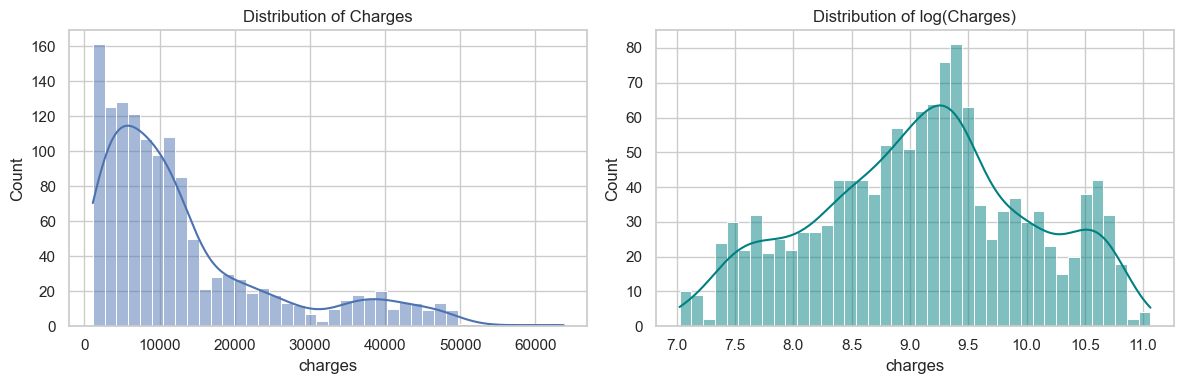

Skewness of charges:      1.52
Skewness of log(charges): -0.09


In [56]:
# Raw charges vs log-transformed charges
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['charges'], bins=40, kde=True, ax=axes[0])
axes[0].set_title('Distribution of Charges')

sns.histplot(np.log1p(df['charges']), bins=40, kde=True, ax=axes[1], color='teal')
axes[1].set_title('Distribution of log(Charges)')

plt.tight_layout()
plt.show()

print('Skewness of charges:     ', round(df['charges'].skew(), 2))
print('Skewness of log(charges):', round(np.log1p(df['charges']).skew(), 2))

**What to look for:** `charges` is strongly right-skewed (a long tail of expensive cases). A log transform pulls it much closer to symmetric, which is worth considering for the linear model later.

### 2.2 Numerical features

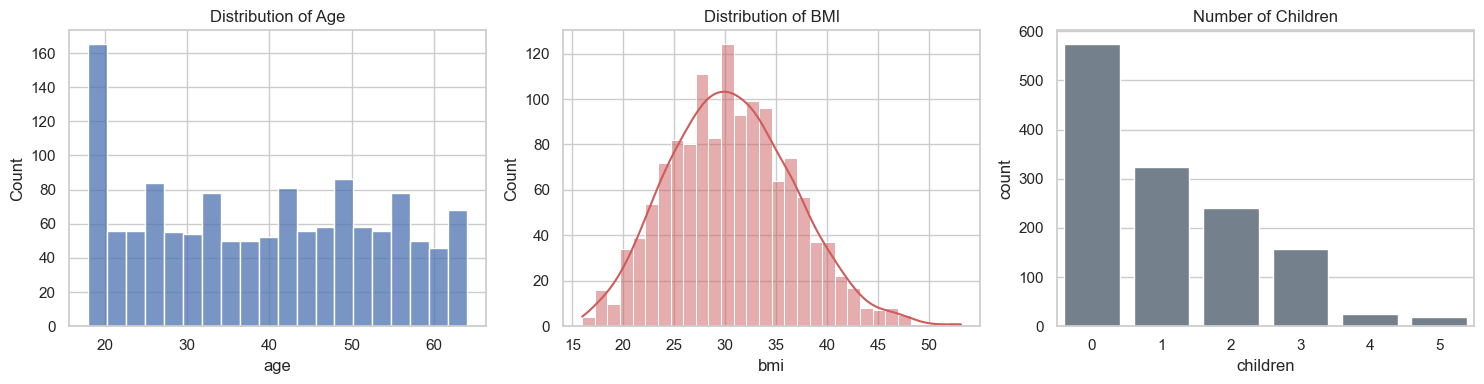

In [57]:
# Histograms of age, bmi and children
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df['age'], bins=20, ax=axes[0])
axes[0].set_title('Distribution of Age')

sns.histplot(df['bmi'], bins=30, kde=True, ax=axes[1], color='indianred')
axes[1].set_title('Distribution of BMI')

sns.countplot(x='children', data=df, ax=axes[2], color='slategray')
axes[2].set_title('Number of Children')

plt.tight_layout()
plt.show()

### 2.3 Outlier check

Box plots plus an IQR count per column. We **inspect** outliers here rather than delete them: high charges are mostly real smokers, and removing them would hide the most important pattern in the data.

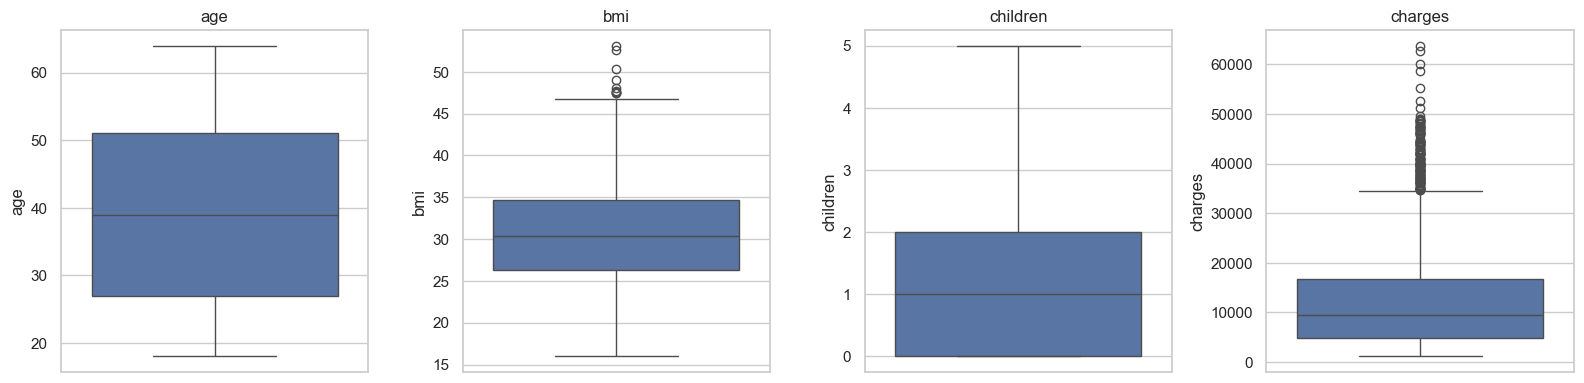

In [58]:
# Box plots on separate axes (columns have very different scales)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [59]:
# Count IQR outliers per column
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

for col in num_cols:
    print(f'{col:<9} outliers: {iqr_outliers(df[col]).sum()}')

age       outliers: 0
bmi       outliers: 9
children  outliers: 0
charges   outliers: 139


In [60]:
# Who are the charges outliers?
charge_outliers = df[iqr_outliers(df['charges'])]
print('Smoker share among charges outliers:')
print(charge_outliers['smoker'].value_counts(normalize=True).round(3))

Smoker share among charges outliers:
smoker
yes   0.98
no    0.02
Name: proportion, dtype: float64


**What to look for:** if most `charges` outliers are smokers, they are genuine signal, not data errors, so we keep them.

### 2.4 Categorical features

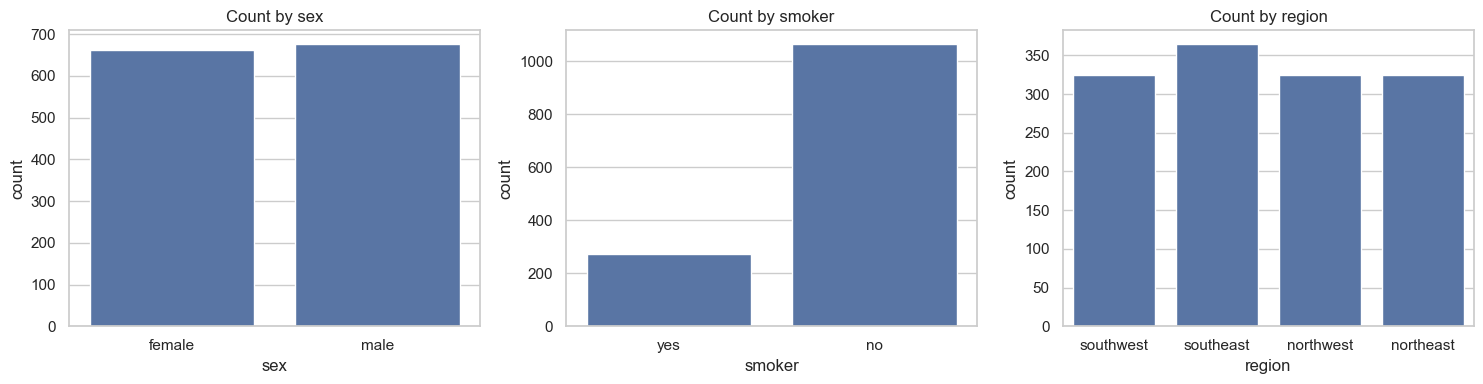

In [61]:
# Counts for each categorical column
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, cat_cols):
    sns.countplot(x=col, data=df, ax=ax)
    ax.set_title(f'Count by {col}')
plt.tight_layout()
plt.show()

### 2.5 Charges vs each feature

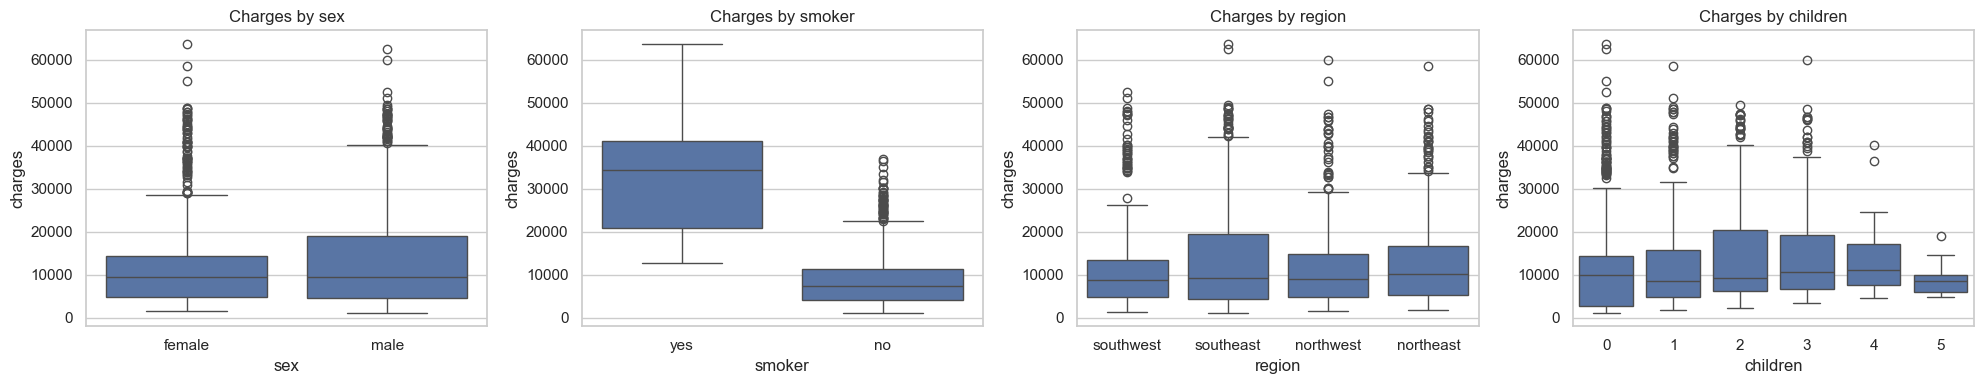

In [62]:
# Charges across categorical features and number of children
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, cat_cols + ['children']):
    sns.boxplot(x=col, y='charges', data=df, ax=ax)
    ax.set_title(f'Charges by {col}')
plt.tight_layout()
plt.show()

In [63]:
# Median charges per group
for col in cat_cols + ['children']:
    print(df.groupby(col)['charges'].median().round(0), '\n')

sex
female   9413.00
male     9378.00
Name: charges, dtype: float64 

smoker
no     7346.00
yes   34456.00
Name: charges, dtype: float64 

region
northeast   10058.00
northwest    8977.00
southeast    9294.00
southwest    8799.00
Name: charges, dtype: float64 

children
0    9863.00
1    8484.00
2    9265.00
3   10601.00
4   11034.00
5    8590.00
Name: charges, dtype: float64 



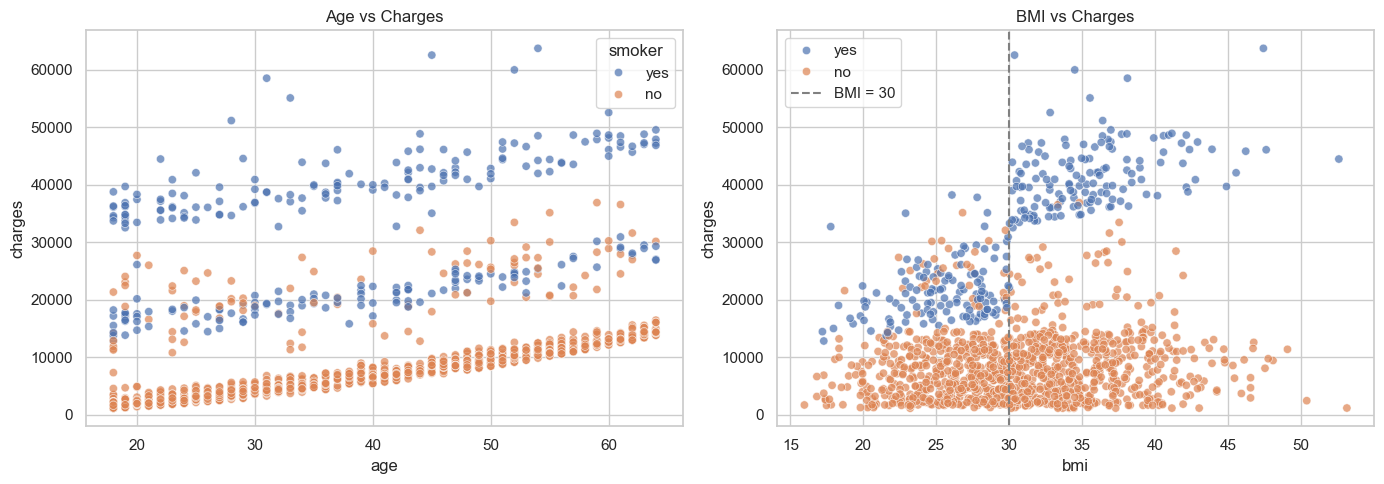

In [64]:
# Age and BMI vs charges, coloured by smoker
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(x='age', y='charges', hue='smoker', data=df, alpha=0.7, ax=axes[0])
axes[0].set_title('Age vs Charges')

sns.scatterplot(x='bmi', y='charges', hue='smoker', data=df, alpha=0.7, ax=axes[1])
axes[1].axvline(30, color='gray', linestyle='--', label='BMI = 30')
axes[1].set_title('BMI vs Charges')
axes[1].legend()

plt.tight_layout()
plt.show()

**What to look for:**
- **Age vs charges:** charges rise steadily with age, in roughly three bands (non-smokers at the bottom, smokers in the upper bands).
- **BMI vs charges:** for non-smokers BMI barely matters; for smokers there is a jump around BMI 30. That is an *interaction* between smoking and BMI, which a single correlation number won't capture.

In [65]:
# Smoking x obesity (BMI >= 30): median charges and group sizes
obese = np.where(df['bmi'] >= 30, 'obese', 'not obese')
print(pd.crosstab(df['smoker'], obese, values=df['charges'], aggfunc='median').round(0))
print()
print(pd.crosstab(df['smoker'], obese))

col_0   not obese    obese
smoker                    
no        6762.00  8084.00
yes      20167.00 40904.00

col_0   not obese  obese
smoker                  
no            502    561
yes           129    145


### 2.6 Correlation

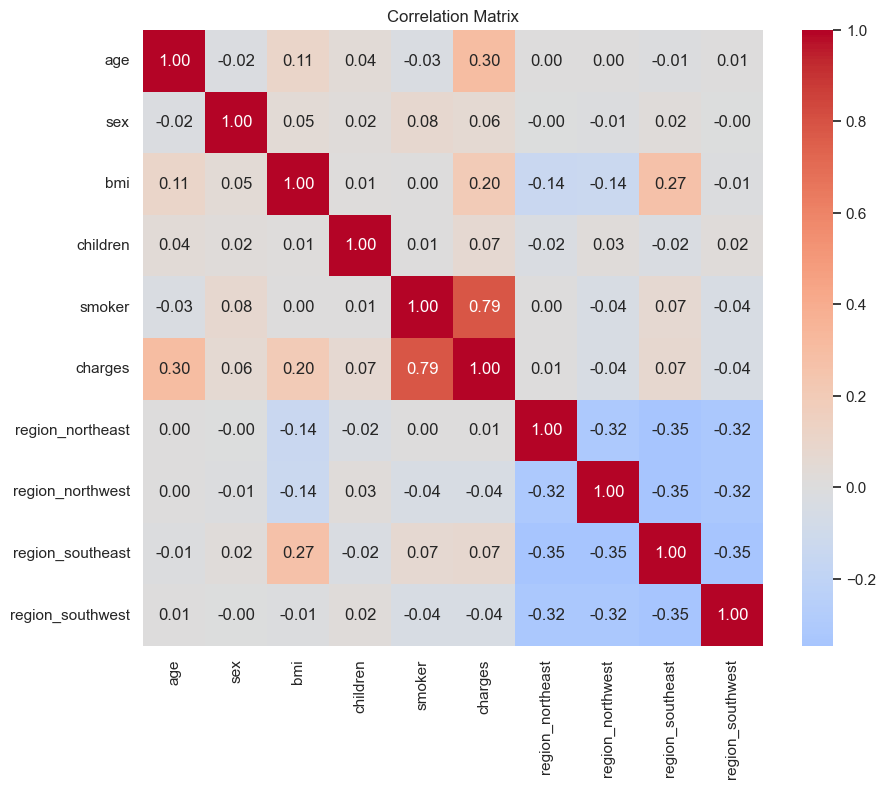

smoker              0.79
age                 0.30
bmi                 0.20
region_southeast    0.07
children            0.07
sex                 0.06
region_southwest   -0.04
region_northwest   -0.04
region_northeast    0.01
Name: charges, dtype: float64

In [66]:
# Temporary numeric encoding just for the correlation matrix
df_corr = df.copy()
df_corr['smoker'] = (df_corr['smoker'] == 'yes').astype(int)
df_corr['sex'] = (df_corr['sex'] == 'male').astype(int)
df_corr = pd.get_dummies(df_corr, columns=['region'], dtype=int)

plt.figure(figsize=(10, 8))
sns.heatmap(df_corr.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

df_corr.corr()['charges'].drop('charges').sort_values(key=abs, ascending=False)

**Note:** correlation only measures *linear, one-variable-at-a-time* relationships. BMI may look weak here even though it matters a lot for smokers (section 2.5), so we won't drop features purely on a correlation threshold.

## 3. Feature Engineering

Plan, based on the EDA:
1. **Encode categories** as numbers: `smoker` and `sex` as 0/1, `region` with one-hot encoding.
2. **Create new features** that capture patterns we saw:
   - `obese` (BMI ≥ 30) and the interaction `smoker_obese`.
   - `age_sq` (age squared) for the slight upward bend in the age vs charges curve.
3. **Create a log target** `log_charges` to reduce skew.
4. **Split** into training and test sets.

### 3.1 Encoding categorical variables

In [67]:
# Work on a copy so the original df stays readable for reference
df_fe = df.copy()

# Binary columns -> 0/1 (explicit mapping, so we know exactly what 1 means)
df_fe['smoker'] = (df_fe['smoker'] == 'yes').astype(int)   # 1 = smoker
df_fe['sex'] = (df_fe['sex'] == 'male').astype(int)         # 1 = male

# Region -> one-hot; drop_first removes 'northeast', which becomes the baseline
df_fe = pd.get_dummies(df_fe, columns=['region'], drop_first=True, dtype=int)

df_fe.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,0,27.90,0,1,16884.92,0,0,1
1,18,1,33.77,1,0,1725.55,0,1,0
2,28,1,33.00,3,0,4449.46,0,1,0
3,33,1,22.70,0,0,21984.47,1,0,0
4,32,1,28.88,0,0,3866.86,1,0,0


**Why `drop_first=True`?** With all four region columns, any one of them can be computed from the other three (they always add up to 1). That redundancy (the *dummy variable trap*) makes linear regression coefficients unstable. Dropping one leaves `northeast` as the reference: each remaining region coefficient means "difference vs northeast".

**Why not LabelEncoder for region?** It would code regions as 0, 1, 2, 3, implying an order (southwest > northeast) that doesn't exist.

### 3.2 New features

In [68]:
# Obesity flag and its interaction with smoking
df_fe['obese'] = (df_fe['bmi'] >= 30).astype(int)
df_fe['smoker_obese'] = df_fe['smoker'] * df_fe['obese']   # 1 only for obese smokers

# Squared age to let a linear model capture a curved age effect
df_fe['age_sq'] = df_fe['age'] ** 2

df_fe[['age', 'age_sq', 'bmi', 'obese', 'smoker', 'smoker_obese']].sample(5, random_state=1)

,age,age_sq,bmi,obese,smoker,smoker_obese
628,44,1936,38.95,1,1,1
1086,57,3249,31.54,1,0,0
283,55,3025,32.40,1,0,0
789,39,1521,41.80,1,0,0
593,41,1681,40.26,1,0,0


**Why these features?**
- **`smoker_obese`**: the crosstab in section 2.5 showed median charges of about \$20.2k for non-obese smokers vs \$40.9k for obese smokers, while for non-smokers obesity only moves the median from \$6.8k to \$8.1k. A linear model adds up effects independently, so it can't learn "smoking *and* obesity together cost extra" unless we give it this column. Tree models can find it on their own, but the explicit feature helps them too.
- **`age_sq`**: lets a linear model fit a curve instead of a straight line for age.
- **Why no `age_group`?** (The original notebook made one.) Binning age into 4 groups throws away detail that `age` already carries, and it was never used in a model anyway.

### 3.3 Log-transformed target

In [69]:
# log1p(x) = log(1 + x); reverse it later with np.expm1
df_fe['log_charges'] = np.log1p(df_fe['charges'])
df_fe[['charges', 'log_charges']].describe()

,charges,log_charges
count,1337.00,1337.00
mean,13279.12,9.10
std,12110.36,0.92
min,1121.87,7.02
25%,4746.34,8.47
50%,9386.16,9.15
75%,16657.72,9.72
max,63770.43,11.06


We'll train models on **both** `charges` and `log_charges` and compare. Predictions from the log model get converted back to dollars with `np.expm1` before evaluation, so all models are scored on the same scale.

### 3.4 Do the new features help?

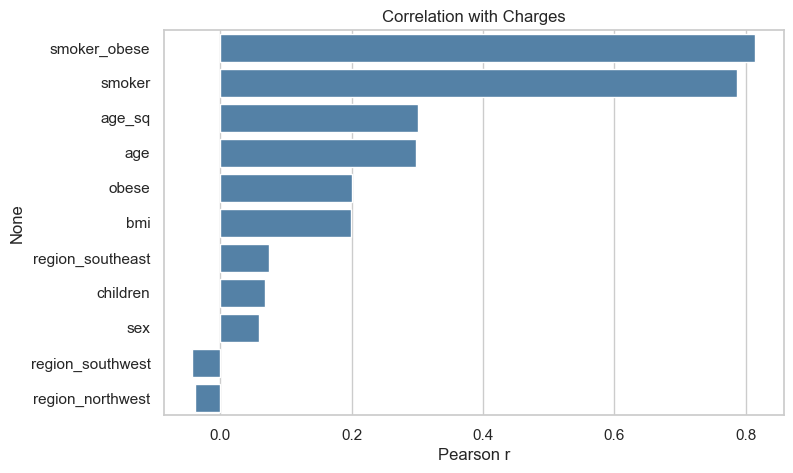

smoker_obese        0.81
smoker              0.79
age_sq              0.30
age                 0.30
obese               0.20
bmi                 0.20
region_southeast    0.07
children            0.07
sex                 0.06
region_southwest   -0.04
region_northwest   -0.04
Name: charges, dtype: float64

In [70]:
# Correlation of every feature with charges, strongest first
corr_with_target = (df_fe.corr()['charges']
                    .drop(['charges', 'log_charges'])
                    .sort_values(key=abs, ascending=False))

plt.figure(figsize=(8, 5))
sns.barplot(x=corr_with_target.values, y=corr_with_target.index, color='steelblue')
plt.title('Correlation with Charges')
plt.xlabel('Pearson r')
plt.show()

corr_with_target

**What to look for:** `smoker_obese` should rank near the top, well above `bmi` and `obese` on their own. That confirms the interaction carries information that BMI alone hides.

### 3.5 Train / test split

In [71]:
from sklearn.model_selection import train_test_split

target_cols = ['charges', 'log_charges']
features = [c for c in df_fe.columns if c not in target_cols]

X = df_fe[features]
y = df_fe['charges']

# stratify on smoker so train and test have the same smoker share
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=X['smoker']
)

# Log targets for the same split
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

print('Features:', features)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print(f"Smoker share - train: {X_train['smoker'].mean():.3f}, test: {X_test['smoker'].mean():.3f}")

Features: ['age', 'sex', 'bmi', 'children', 'smoker', 'region_northwest', 'region_southeast', 'region_southwest', 'obese', 'smoker_obese', 'age_sq']
Train: (1069, 11)  Test: (268, 11)
Smoker share - train: 0.205, test: 0.205


**Notes on the split:**
- **`stratify`**: only about 1 in 5 people smoke, and smoking drives charges more than anything else. Stratifying guarantees the test set isn't accidentally light or heavy on smokers.
- **`random_state=42`**: makes the split reproducible.
- **Scaling** is deliberately *not* done here. For linear models we'll scale inside a pipeline during modelling, so the scaler learns only from training data (no leakage from the test set). Tree models don't need scaling.

## 4. Modelling

Every model is compared with the same setup:
- **5-fold cross-validation on the training set only.** `cross_val_predict` gives each row of `X_train` a prediction from a model that never saw that row, and the metrics are computed on those out-of-fold predictions. The test set stays untouched until the final model is chosen.
- **Scored in dollars.** Predictions from models trained on `log_charges` are converted back with `np.expm1` first, so every row of the results table is comparable.
- **Metrics:** MAE is the typical error in dollars. RMSE punishes big misses more. R² is the share of variation explained, where 0 means no better than always predicting the mean.

In [ ]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

cv = KFold(n_splits=5, shuffle=True, random_state=42)
results = {}   # keyed by (model, target), so re-running a cell overwrites its row

def evaluate(name, model, log_target=False):
    """Cross-validate on the training set and store MAE / RMSE / R2 in dollars."""
    y_fit = y_train_log if log_target else y_train
    pred = cross_val_predict(model, X_train, y_fit, cv=cv)
    if log_target:
        pred = np.expm1(pred)   # back to dollars before scoring
    target = 'log_charges' if log_target else 'charges'
    results[(name, target)] = {
        'model': name,
        'target': target,
        'MAE': mean_absolute_error(y_train, pred),
        'RMSE': np.sqrt(mean_squared_error(y_train, pred)),
        'R2': r2_score(y_train, pred),
    }
    return pred

def show_results():
    return pd.DataFrame(results.values()).sort_values('MAE').reset_index(drop=True)

### 4.1 Baseline

A "model" that ignores every feature and predicts the same number for everyone. It sets the floor that any real model has to beat clearly.

In [ ]:
from sklearn.dummy import DummyRegressor

# Ignore all features and predict one constant for everybody
evaluate('Baseline (mean)', DummyRegressor(strategy='mean'))
evaluate('Baseline (median)', DummyRegressor(strategy='median'))

show_results()

**What to look for:** the baseline MAE is around \$8–9k, which is the number every real model has to beat.

The two baselines also show how the metric changes the winner. R² compares a model against always predicting the mean, so the mean baseline scores about 0 by definition. The median sits below the mean in this skewed data: it has a **better MAE** but a slightly **negative R²**.

### 4.2 Linear models

Three linear models, each scaled inside a pipeline:
- **`LinearRegression`**: plain least squares.
- **`RidgeCV`**: shrinks all coefficients a little. That's useful here because `age`/`age_sq` and `bmi`/`obese` are strongly correlated pairs. The `CV` version picks the shrinkage strength (`alpha`) with its own internal cross-validation.
- **`LassoCV`**: like Ridge, but it can shrink unhelpful coefficients all the way to zero, which works as automatic feature selection.

Each model is trained on both `charges` and `log_charges`.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV

# Scaler inside the pipeline: during CV it is refit on each training fold only
linear_models = {
    'Linear': make_pipeline(StandardScaler(), LinearRegression()),
    'Ridge': make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 50))),
    'Lasso': make_pipeline(StandardScaler(), LassoCV(max_iter=50000)),
}

for name, model in linear_models.items():
    for log_target in [False, True]:
        evaluate(name, model, log_target)

show_results()

**What to look for:**
- All three linear models on `charges` land around **MAE \$2.6k and R² 0.85**, about a third of the baseline's error. Ridge and Lasso barely differ from plain regression: with 11 features and about 1,000 rows there is little overfitting for regularization to fix.
- The `log_charges` versions are clearly **worse** (R² about 0.5), even though the log target looked much nicer in 2.1. The likely reasons:
  1. **Effects become multiplicative.** In log space, "smoker" means "multiply charges by some percentage", so the model makes smoking cost more for older people. In the data, smoking adds a roughly constant amount (the parallel bands in the age plot in 2.5), so the log model under-predicts young smokers and over-predicts old ones.
  2. **Back-transform bias.** `expm1` of a predicted log value estimates something closer to the median than the mean, which adds to the error in dollars.
- **Lesson:** a skewed target alone isn't a reason to log-transform. What matters is whether the effects add or multiply, and here they mostly add. The log target may still do fine with tree models, which assume neither.

In [ ]:
# Coefficients of the raw-target models, refit on the full training set
lin = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
lasso = make_pipeline(StandardScaler(), LassoCV(max_iter=50000)).fit(X_train, y_train)

coefs = pd.DataFrame({'Linear': lin[-1].coef_, 'Lasso': lasso[-1].coef_}, index=features)
coefs = coefs.sort_values('Linear', key=abs, ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=coefs['Linear'], y=coefs.index, color='steelblue')
plt.title('Linear Regression Coefficients (scaled features)')
plt.xlabel('Change in charges ($) per 1 std increase')
plt.show()

print(f"Intercept: {lin[-1].intercept_:.0f}   Lasso alpha: {lasso[-1].alpha_:.1f}")
coefs

**What to look for:** with scaled features, each coefficient is the change in predicted charges for a one-standard-deviation increase in that feature. For 0/1 columns that is a one-SD shift, not exactly "yes vs no". The intercept is simply the mean of `y_train`.
- `smoker_obese` and `smoker` are the top two, so the interaction feature from 3.2 earns its place.
- `age` is negative while `age_sq` is large and positive. That does **not** mean older people are cheaper. Over ages 18–64 the two columns are almost perfectly correlated (r ≈ 0.99), so the model splits the age effect between them arbitrarily. Lasso shows this by setting `age` to zero and letting `age_sq` carry all of it.
- `sex` and the region coefficients are small (a few hundred dollars), which matches the EDA.